In [1]:
import json
import logging
import sys
from datetime import datetime
from pathlib import Path
from typing import Any

import geopandas as gpd
import earthaccess

# Put the project root on sys.path so we can import our own modules.
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Set up logging so library messages appear in the notebook.
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-8s  %(name)s  %(message)s",
)
logger = logging.getLogger("extraction_notebook")

print(f"earthaccess version: {earthaccess.__version__}")
print(f"Project root: {PROJECT_ROOT}")

def authenticate() -> None:
    """Authenticate to NASA Earthdata.

    Uses earthaccess.login() which checks, in order:
        1. Existing valid token in ~/.earthaccess/
        2. Credentials in .netrc / _netrc
        3. Interactive prompt

    No credentials are stored in this codebase.
    """
    earthaccess.login()
    logger.info("Authenticated to NASA Earthdata.")


authenticate()
print("Authentication successful.")

earthaccess version: 0.18.0
Project root: C:\Users\huckr\Desktop\JPL\Code\EMIT


2026-06-23 14:09:32,940  INFO      earthaccess.auth  You're now authenticated with NASA Earthdata Login
2026-06-23 14:09:32,943  INFO      earthaccess.auth  Using token with expiration date 08/14/2026
2026-06-23 14:09:35,447  INFO      extraction_notebook  Authenticated to NASA Earthdata.


Authentication successful.


## This script plots a given PICS and identifies the centroid

  Centroid vs. reported center offset: 16.9 m


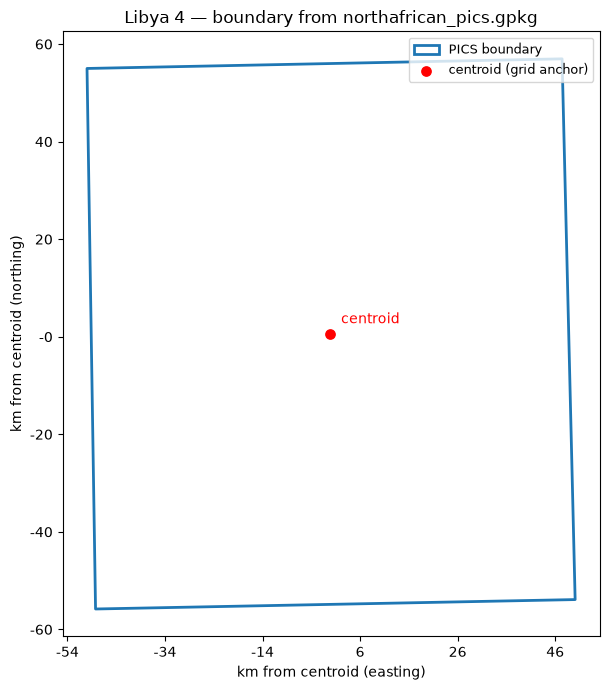

In [2]:
# Cell 1 — imports
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Cell 2 — load the existing PICS boundaries from the gpkg
PICS_PATH = r"C:\Users\huckr\Desktop\JPL\Data\ROIs\northafrican_pics.gpkg"

pics_gdf = gpd.read_file(PICS_PATH)

# Cell 3 — select a site
PICS_NAME = "Libya 4"

site = pics_gdf[pics_gdf["site_name"] == PICS_NAME]

# Pull this site's attributes straight from the gpkg row
row = site.iloc[0]

# Cell 4 — project to UTM and take the anchor from the polygon
utm_crs = site.estimate_utm_crs()
site_utm = site.to_crs(utm_crs)

# Grid anchor = planimetric centroid of the gpkg polygon
centroid = site_utm.geometry.iloc[0].centroid
cx, cy = centroid.x, centroid.y

minx, miny, maxx, maxy = site_utm.total_bounds

# Cross-check: does the polygon centroid agree with the gpkg's reported center?
center_pt = gpd.GeoSeries.from_xy(
    [row["center_lon"]], [row["center_lat"]], crs="EPSG:4326"
).to_crs(utm_crs).iloc[0]
offset_m = centroid.distance(center_pt)
print(f"  Centroid vs. reported center offset: {offset_m:.1f} m")

# Cell 5 — display the loaded PICS boundary + its centroid
fig, ax = plt.subplots(figsize=(7, 7))
site_utm.plot(ax=ax, facecolor="none", edgecolor="C0", linewidth=2, label="PICS boundary")
ax.scatter([cx], [cy], color="red", s=45, zorder=3, label="centroid (grid anchor)")
ax.annotate("centroid", (cx, cy), textcoords="offset points", xytext=(8, 8), color="red")
ax.xaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{(t - cx)/1000:.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda t, _: f"{(t - cy)/1000:.0f}"))
ax.set_xlabel("km from centroid (easting)")
ax.set_ylabel("km from centroid (northing)")
ax.set_title(f"{PICS_NAME} — boundary from northafrican_pics.gpkg")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# Tiles PICS into grid anchored on centroid of increasing size

Libya 4: site extent 100.1 x 112.8 km
Candidate patch sizes (km): [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
 size_km  n_patches
      10         80
      20         16
      30          4
      40          4

Total fully-contained patches: 104
Sizes with >=1 contained patch: [np.int64(10), np.int64(20), np.int64(30), np.int64(40)] km

Patch IDs by size:
  10 km: ['10_9_0', '10_8_0', '10_7_0', '10_6_0', '10_5_0', '10_4_0', '10_3_0', '10_2_0', '10_1_0', '10_0_0', '10_9_1', '10_8_1', '10_7_1', '10_6_1', '10_5_1', '10_4_1', '10_3_1', '10_2_1', '10_1_1', '10_0_1', '10_9_2', '10_8_2', '10_7_2', '10_6_2', '10_5_2', '10_4_2', '10_3_2', '10_2_2', '10_1_2', '10_0_2', '10_9_3', '10_8_3', '10_7_3', '10_6_3', '10_5_3', '10_4_3', '10_3_3', '10_2_3', '10_1_3', '10_0_3', '10_9_4', '10_8_4', '10_7_4', '10_6_4', '10_5_4', '10_4_4', '10_3_4', '10_2_4', '10_1_4', '10_0_4', '10_9_5', '10_8_5', '10_7_5', '10_6_5', '10_5_5', '10_4_5', '10_3_5', '10_2_5', '10_1_5', '10_0_5', '10_9_6', '10_8_6', '10_7_6', '10_

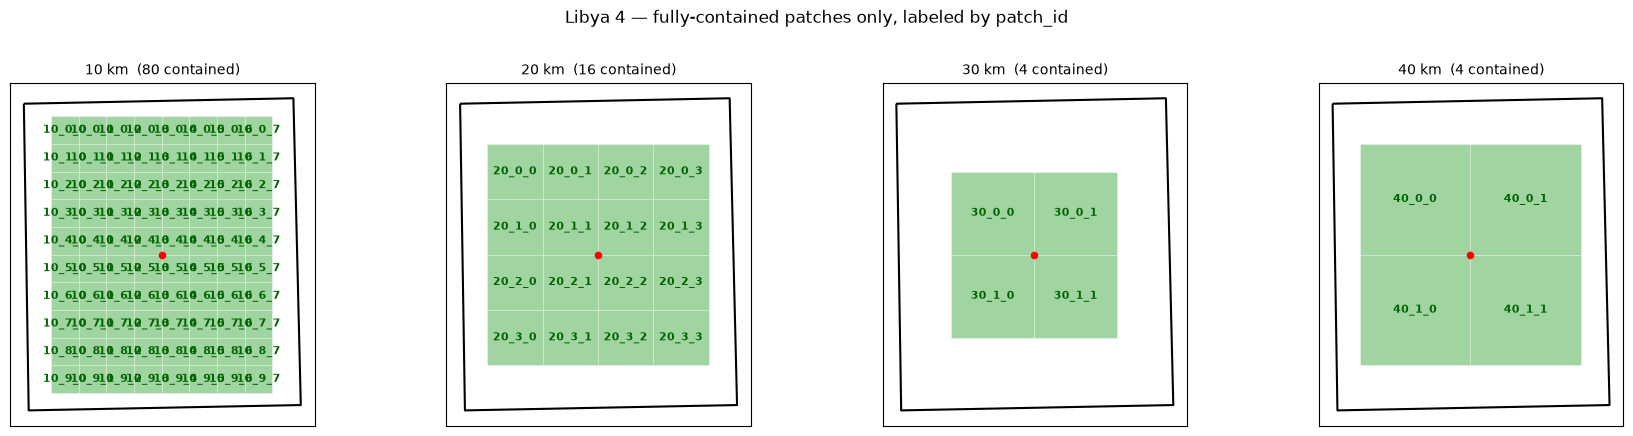

In [3]:
# Cell 6 — tiling parameters and helper
import math
import numpy as np
import pandas as pd
from shapely.geometry import box

BASE_KM = 10   # base box size; larger patches are NxN blocks of these

site_polygon = site_utm.geometry.iloc[0]
minx, miny, maxx, maxy = site_utm.total_bounds
max_extent_km = min(maxx - minx, maxy - miny) / 1000
PATCH_SIZES_KM = [BASE_KM * n for n in range(1, int(max_extent_km // BASE_KM) + 1)]
print(f"{PICS_NAME}: site extent {(maxx-minx)/1000:.1f} x {(maxy-miny)/1000:.1f} km")
print(f"Candidate patch sizes (km): {PATCH_SIZES_KM}")


def tile_size(cx, cy, size_m, bounds, polygon):
    """Square patches on a centroid-anchored grid that fall ENTIRELY within
    `polygon`. Partial/clipped patches are discarded. Row/col are then assigned
    over only the retained patches, normalized so the top-left retained patch
    is (0, 0): row increases downward (north -> south), col rightward (west -> east)."""
    minx, miny, maxx, maxy = bounds
    i0 = math.floor((minx - cx) / size_m)
    i1 = math.ceil((maxx - cx) / size_m)
    j0 = math.floor((miny - cy) / size_m)
    j1 = math.ceil((maxy - cy) / size_m)
    size_km = int(size_m / 1000)

    # First pass: keep only fully-contained boxes, recording their grid (i, j).
    kept = []
    for i in range(i0, i1):
        for j in range(j0, j1):
            x0, y0 = cx + i * size_m, cy + j * size_m
            patch = box(x0, y0, x0 + size_m, y0 + size_m)
            frac = patch.intersection(polygon).area / patch.area
            if frac > 0.999:
                kept.append((i, j, patch))

    if not kept:
        return []   # no fully-contained patch at this size

    # Normalize row/col over the retained set only (contiguous, no gaps).
    i_vals = sorted({i for i, _, _ in kept})
    j_vals = sorted({j for _, j, _ in kept})
    col_of = {i: c for c, i in enumerate(i_vals)}                 # west -> east, 0..
    row_of = {j: r for r, j in enumerate(reversed(j_vals))}        # north -> south, 0..

    out = []
    for i, j, patch in kept:
        row, col = row_of[j], col_of[i]
        out.append({
            "patch_id": f"{size_km}_{row}_{col}",
            "size_km": size_km,
            "row": row,
            "col": col,
            "n_base": int(size_km / BASE_KM),
            "fully_inside": True,
            "geometry": patch,
        })
    return out


# Cell 7 — build the patch GeoDataFrame (fully-contained patches only)
records = []
for size_km in PATCH_SIZES_KM:
    records.extend(tile_size(cx, cy, size_km * 1000, (minx, miny, maxx, maxy), site_polygon))

patches_gdf = gpd.GeoDataFrame(records, crs=utm_crs)

# Sizes that actually have at least one fully-contained patch.
KEPT_SIZES_KM = sorted(patches_gdf["size_km"].unique()) if len(patches_gdf) else []

summary = (
    patches_gdf.groupby("size_km")
    .agg(n_patches=("patch_id", "size"))
    .reset_index()
)
print(summary.to_string(index=False))
print(f"\nTotal fully-contained patches: {len(patches_gdf)}")
print(f"Sizes with >=1 contained patch: {KEPT_SIZES_KM} km")
print("\nPatch IDs by size:")
for size_km in KEPT_SIZES_KM:
    ids = patches_gdf[patches_gdf["size_km"] == size_km]["patch_id"].tolist()
    print(f"  {size_km} km: {ids}")


# Cell 8 — display small multiples, only sizes with contained patches, labeled by ID
if not KEPT_SIZES_KM:
    print("No fully-contained patches at any size; nothing to plot.")
else:
    n = len(KEPT_SIZES_KM)
    ncols = min(4, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.4 * nrows), squeeze=False)
    axes = axes.ravel()

    for ax, size_km in zip(axes, KEPT_SIZES_KM):
        sub = patches_gdf[patches_gdf["size_km"] == size_km]
        site_utm.boundary.plot(ax=ax, color="black", linewidth=1.5, zorder=3)
        sub.plot(ax=ax, facecolor="C2", edgecolor="white", alpha=0.45, linewidth=0.5)
        ax.scatter([cx], [cy], color="red", s=20, zorder=5)

        label_fs = max(5, min(8, 90 / max(1, np.sqrt(len(sub)))))
        for _, p in sub.iterrows():
            px, py = p.geometry.centroid.x, p.geometry.centroid.y
            ax.annotate(p["patch_id"], (px, py), ha="center", va="center",
                        fontsize=label_fs, color="darkgreen", fontweight="bold", zorder=6)

        ax.set_title(f"{size_km} km  ({len(sub)} contained)", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect("equal")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(f"{PICS_NAME} — fully-contained patches only, labeled by patch_id",
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

## ID granules that intersect PICS

In [4]:
from datetime import datetime
from shapely.geometry import Polygon

# Product collections
EMIT_PRODUCTS = {
    "L1B_RAD": "EMITL1BRAD",
    "L2A_RFL": "EMITL2ARFL",
}

# Search date range
DATE_START_ALL = "2022-08-01"
DATE_END_ALL   = "2026-06-18"

# Helpers used by the footprint script
def granule_footprint(umm):
    """Reconstruct a granule's footprint polygon (EPSG:4326) from its UMM GPolygon."""
    try:
        gp = umm["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"]
        pts = gp[0]["Boundary"]["Points"]
        return Polygon([(p["Longitude"], p["Latitude"]) for p in pts])
    except (KeyError, TypeError, IndexError):
        return None

def acquisition_time(umm):
    try:
        t = umm["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]
        return datetime.strptime(t.rstrip("Z").split(".")[0], "%Y-%m-%dT%H:%M:%S")
    except (KeyError, TypeError, ValueError):
        return None

In [12]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from datetime import datetime
from shapely.geometry import Polygon
from matplotlib.lines import Line2D

# ============================================================
# CONFIG
# ============================================================
FOOTPRINT_SITE    = "Libya 4"
FOOTPRINT_PRODUCT = "L2A_RFL"        # "L1B_RAD" or "L2A_RFL"
short_name = EMIT_PRODUCTS[FOOTPRINT_PRODUCT]

# ============================================================
# COLLECT FOOTPRINTS overlapping the PICS boundary
# ============================================================
srow = pics_gdf[pics_gdf["site_name"] == FOOTPRINT_SITE].iloc[0]
site_4326 = gpd.GeoSeries([srow.geometry], crs=pics_gdf.crs).to_crs(4326).iloc[0]
w, s, e, n = site_4326.bounds

results = earthaccess.search_data(
    short_name=short_name,
    bounding_box=(w, s, e, n),
    temporal=(DATE_START_ALL, DATE_END_ALL),
    count=-1,
)

scenes = []   # (datetime, cloud_cover, footprint_polygon)
for g in results:
    umm = g["umm"]
    fp = granule_footprint(umm)
    dt = acquisition_time(umm)
    if fp is None or dt is None:
        continue
    scenes.append((dt, umm.get("CloudCover"), fp))

scenes.sort(key=lambda x: x[0])
print(f"{FOOTPRINT_SITE} / {FOOTPRINT_PRODUCT}: {len(scenes)} scene(s) overlapping the PICS")

2026-06-23 14:52:34,206  INFO      earthaccess.api  Granules found: 78


Libya 4 / L2A_RFL: 78 scene(s) overlapping the PICS


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()


## plot granule footprints over PICS (warning - run time is long)

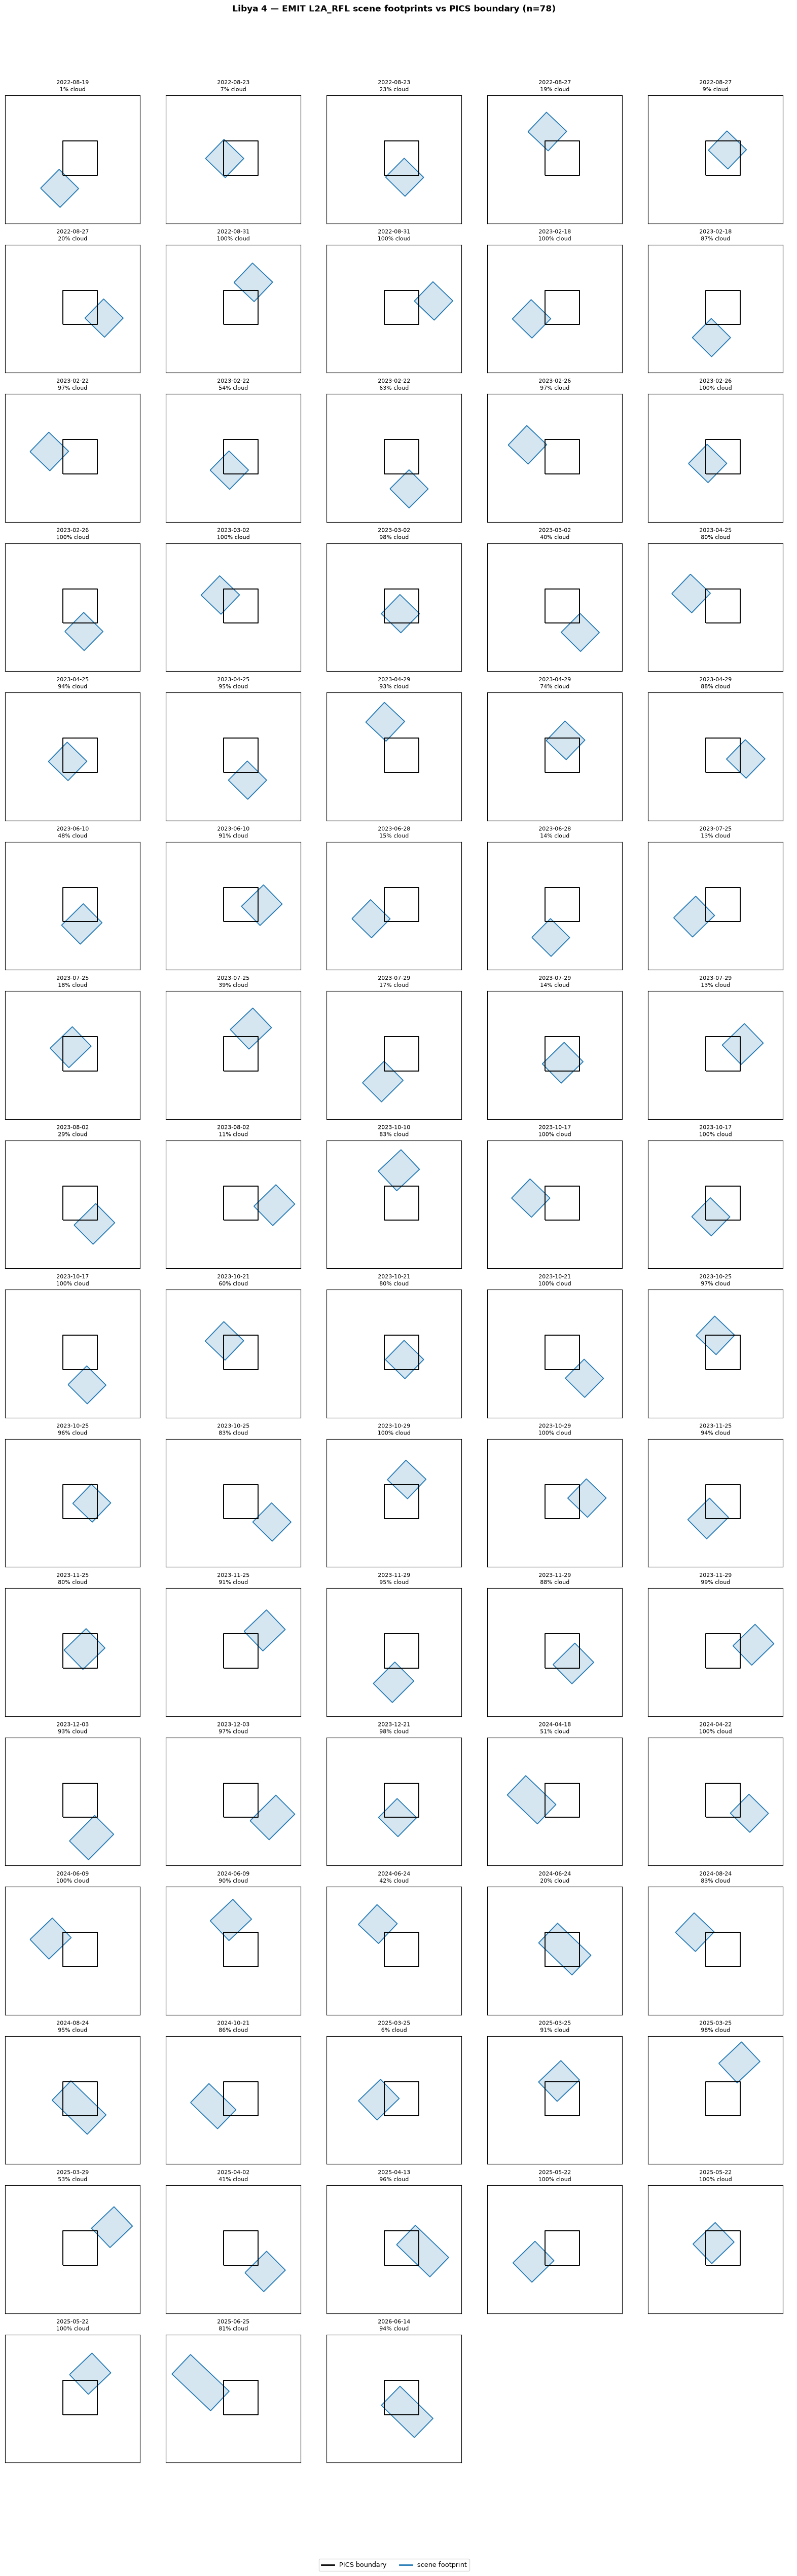

In [13]:
# ============================================================
# PLOT — one panel per scene footprint over the PICS boundary
# ============================================================
if not scenes:
    print("No scenes to plot.")
else:
    n_scenes = len(scenes)
    ncols = min(5, n_scenes)
    nrows = int(np.ceil(n_scenes / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows),
                             squeeze=False)
    axes = axes.ravel()

    # Shared extent across panels so footprints are positionally comparable.
    all_geoms = [site_4326] + [sc[2] for sc in scenes]
    xs = [c for g in all_geoms for c in (g.bounds[0], g.bounds[2])]
    ys = [c for g in all_geoms for c in (g.bounds[1], g.bounds[3])]
    pad_x = (max(xs) - min(xs)) * 0.05
    pad_y = (max(ys) - min(ys)) * 0.05
    xlim = (min(xs) - pad_x, max(xs) + pad_x)
    ylim = (min(ys) - pad_y, max(ys) + pad_y)

    for ax, (dt, cc, fp) in zip(axes, scenes):
        gpd.GeoSeries([fp], crs="EPSG:4326").plot(
            ax=ax, facecolor="C0", edgecolor="C0", alpha=0.18, linewidth=1.2)
        gpd.GeoSeries([fp], crs="EPSG:4326").boundary.plot(
            ax=ax, color="C0", linewidth=1.2)
        gpd.GeoSeries([site_4326], crs="EPSG:4326").boundary.plot(
            ax=ax, color="black", linewidth=1.4, zorder=3)

        cc_txt = f"{cc:.0f}% cloud" if cc is not None else "cloud N/A"
        ax.set_title(f"{dt:%Y-%m-%d}\n{cc_txt}", fontsize=8)
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect("equal")

    for ax in axes[n_scenes:]:
        ax.axis("off")

    legend = [
        Line2D([0], [0], color="black", lw=2, label="PICS boundary"),
        Line2D([0], [0], color="C0", lw=2, label="scene footprint"),
    ]
    fig.legend(handles=legend, loc="lower center", ncol=2, fontsize=9,
               frameon=True, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(
        f"{FOOTPRINT_SITE} — EMIT {FOOTPRINT_PRODUCT} scene footprints vs PICS boundary "
        f"(n={n_scenes})", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.show()

## Identifies and visualizes EMIT coverage by patch

Libya 4: 80 fully-contained 10 km patch(es)



2026-06-23 14:10:32,440  INFO      earthaccess.api  Granules found: 78
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()


  L1B_RAD: 78 scene(s) overlapping the PICS (cached)


2026-06-23 14:10:33,340  INFO      earthaccess.api  Granules found: 78


  L2A_RFL: 78 scene(s) overlapping the PICS (cached)

Patch IDs and fully-covering granule counts (10 km):
  patch_id         RAD   RFL
  --------------------------
  10_7_1            14    14
  10_6_2            14    14
  10_8_0            13    13
  10_7_0            13    13
  10_6_0            13    13
  10_6_1            13    13
  10_9_2            13    13
  10_8_3            13    13
  10_9_4            13    13
  10_7_7            13    13
  10_8_1            12    12
  10_5_1            12    12
  10_5_2            12    12
  10_9_3            12    12
  10_7_3            12    12
  10_8_4            12    12
  10_7_4            12    12
  10_4_4            12    12
  10_9_5            12    12
  10_8_5            12    12
  10_8_6            12    12
  10_6_6            12    12
  10_4_0            11    11
  10_8_2            11    11
  10_5_3            11    11
  10_3_3            11    11
  10_6_4            11    11
  10_3_4            11    11
  10_7_5            11 

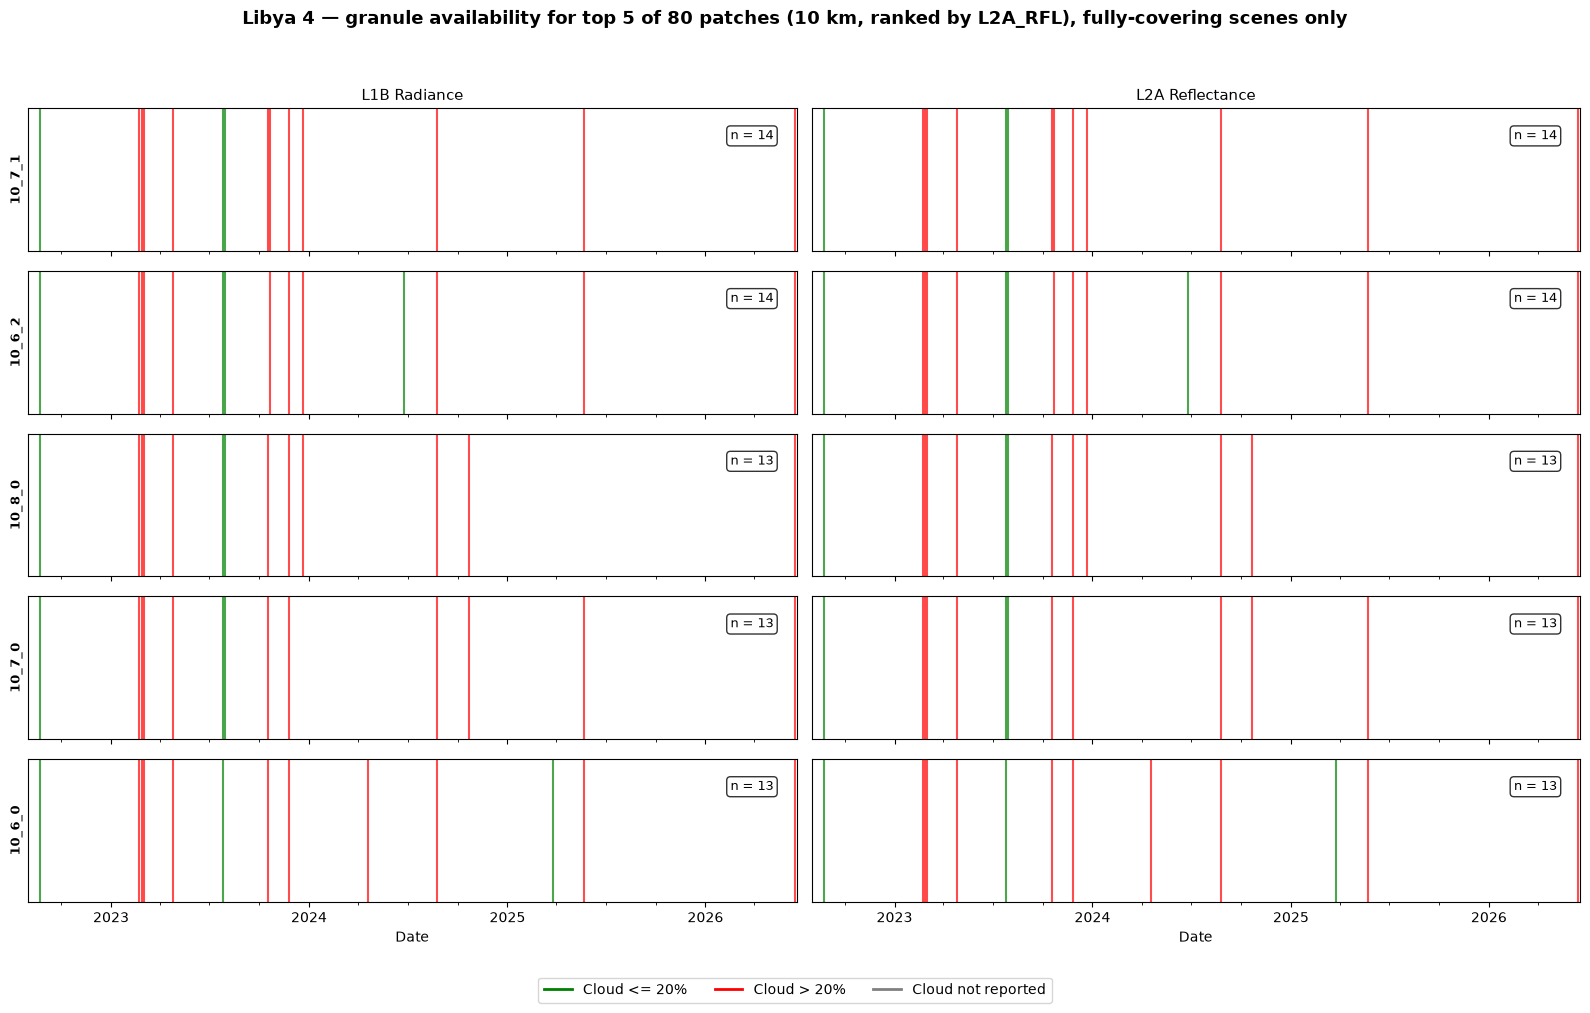

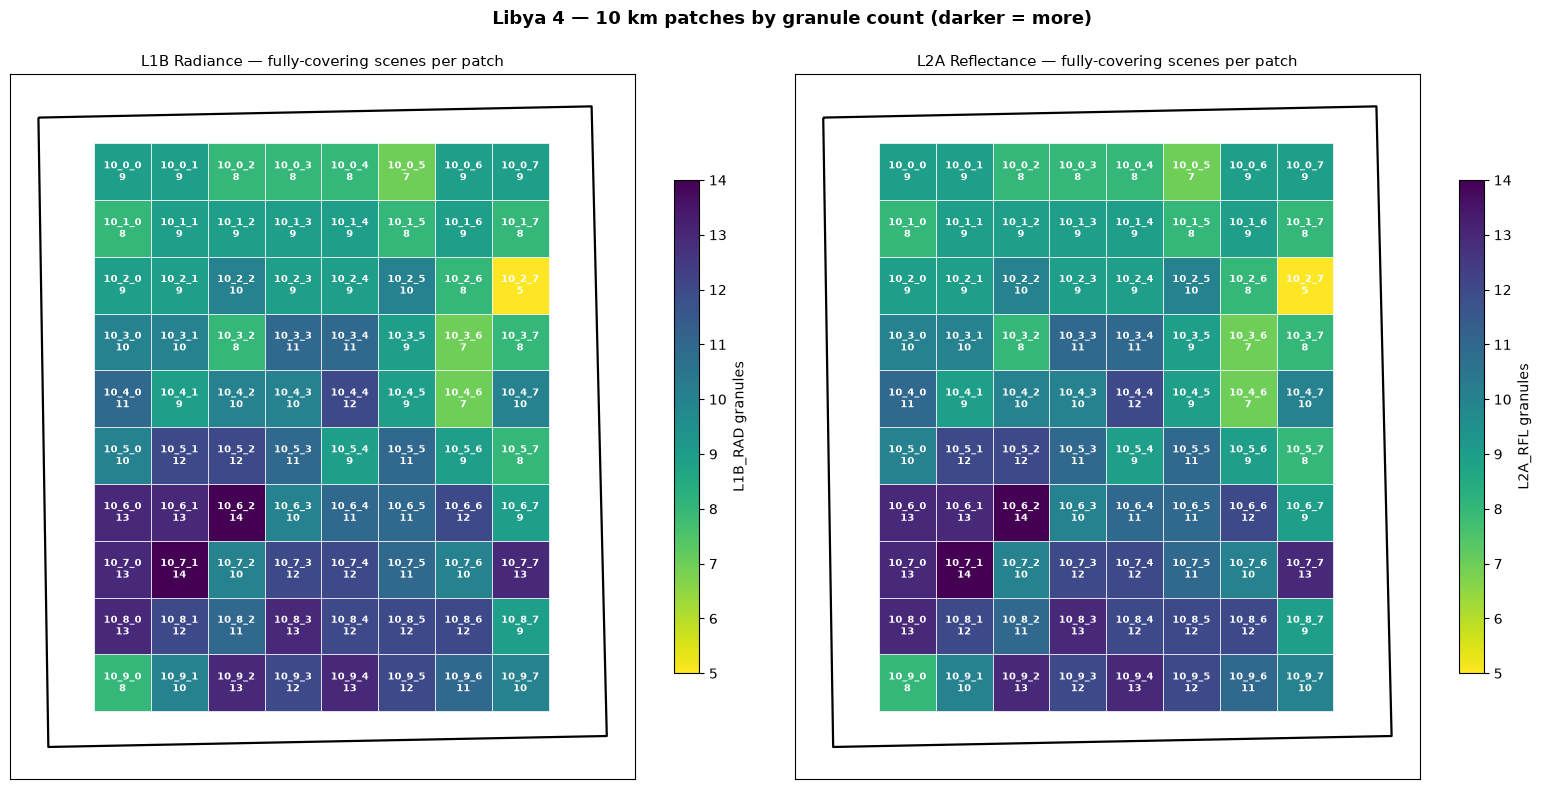

In [6]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

# ============================================================
# CONFIG  (assumes patches_gdf, pics_gdf, PICS_NAME, EMIT_PRODUCTS,
#          DATE_START_ALL/END_ALL, granule_footprint, acquisition_time exist)
# ============================================================
TS_PATCH_SIZE_KM = 10          # which patch size to analyze; must exist in patches_gdf
CLOUD_THRESHOLD  = 20          # percent, for line coloring
TOP_N_PANELS     = 5           # plot time series for the N patches with most granules
RANK_PRODUCT     = "L2A_RFL"   # product whose count drives top-N ranking

# --- validate requested size ---
available_sizes = sorted(patches_gdf["size_km"].unique())
if TS_PATCH_SIZE_KM not in available_sizes:
    raise ValueError(
        f"Patch size {TS_PATCH_SIZE_KM} km not in patches_gdf. "
        f"Available sizes: {available_sizes} km"
    )

size_patches = patches_gdf[patches_gdf["size_km"] == TS_PATCH_SIZE_KM].copy()
print(f"{PICS_NAME}: {len(size_patches)} fully-contained {TS_PATCH_SIZE_KM} km patch(es)\n")


def granule_ur(umm):
    """Granule unique identifier (e.g. EMIT_L2A_RFL_001_...), or None."""
    return umm.get("GranuleUR")


# ============================================================
# CACHED SEARCH — one query per product over the whole site, footprints kept
# ============================================================
srow = pics_gdf[pics_gdf["site_name"] == PICS_NAME].iloc[0]
site_4326 = gpd.GeoSeries([srow.geometry], crs=pics_gdf.crs).to_crs(4326).iloc[0]
w, s, e, n = site_4326.bounds

# scene_cache[product_label] = list of dicts: {ur, dt, cc, fp}
scene_cache = {}
for label, short_name in EMIT_PRODUCTS.items():
    results = earthaccess.search_data(
        short_name=short_name,
        bounding_box=(w, s, e, n),
        temporal=(DATE_START_ALL, DATE_END_ALL),
        count=-1,
    )
    scenes = []
    for g in results:
        umm = g["umm"]
        fp = granule_footprint(umm)
        dt = acquisition_time(umm)
        if fp is None or dt is None:
            continue
        scenes.append({"ur": granule_ur(umm), "dt": dt,
                       "cc": umm.get("CloudCover"), "fp": fp})
    scenes.sort(key=lambda s_: s_["dt"])
    scene_cache[label] = scenes
    print(f"  {label}: {len(scenes)} scene(s) overlapping the PICS (cached)")

# ============================================================
# PER-PATCH: which cached scenes fully contain each patch
# ============================================================
# patch_series[patch_id][label] = list of {ur, dt, cc}
# patch_granules[patch_id][label] = list of granule URs (the requested ID record)
patch_series = {}
patch_granules = {}

for _, prow in size_patches.iterrows():
    pid = prow["patch_id"]
    patch_4326 = gpd.GeoSeries([prow.geometry], crs=patches_gdf.crs).to_crs(4326).iloc[0]

    patch_series[pid] = {}
    patch_granules[pid] = {}
    for label, scenes in scene_cache.items():
        hits = [{"ur": sc["ur"], "dt": sc["dt"], "cc": sc["cc"]}
                for sc in scenes if sc["fp"].contains(patch_4326)]
        patch_series[pid][label] = hits
        patch_granules[pid][label] = [h["ur"] for h in hits]

# per-product count per patch
def n_count(pid, label):
    return len(patch_series[pid][label])

# ============================================================
# PRINT: all patch IDs, per-product counts, and the granule UR lists
# ============================================================
print(f"\nPatch IDs and fully-covering granule counts ({TS_PATCH_SIZE_KM} km):")
print(f"  {'patch_id':<14} {'RAD':>5} {'RFL':>5}")
print("  " + "-" * 26)
for pid in sorted(patch_series, key=lambda p: n_count(p, RANK_PRODUCT), reverse=True):
    print(f"  {pid:<14} {n_count(pid,'L1B_RAD'):>5} {n_count(pid,'L2A_RFL'):>5}")

# patch_granules is the linked ID record: patch_id -> product -> [granule URs]
print(f"\nGranule UR lists are stored in `patch_granules[patch_id][product_label]`.")
print(f"Example — {sorted(patch_series, key=lambda p: n_count(p, RANK_PRODUCT), reverse=True)[0]} / {RANK_PRODUCT}:")
_ex = sorted(patch_series, key=lambda p: n_count(p, RANK_PRODUCT), reverse=True)[0]
for ur in patch_granules[_ex][RANK_PRODUCT][:5]:
    print(f"    {ur}")
if len(patch_granules[_ex][RANK_PRODUCT]) > 5:
    print(f"    ... ({len(patch_granules[_ex][RANK_PRODUCT])} total)")

# ============================================================
# FIGURE 1 — time series, top-N patches by RANK_PRODUCT, 2 cols (RAD, RFL) x N rows
# ============================================================
top_ids = sorted(patch_series, key=lambda p: n_count(p, RANK_PRODUCT), reverse=True)[:TOP_N_PANELS]
product_labels = list(EMIT_PRODUCTS.keys())
product_titles = {"L1B_RAD": "L1B Radiance", "L2A_RFL": "L2A Reflectance"}

x_start, x_end = mdates.datestr2num(DATE_START_ALL), mdates.datestr2num(DATE_END_ALL)

fig, axes = plt.subplots(
    len(top_ids), 2,
    figsize=(16, max(2.5, 2.0 * len(top_ids))),
    sharex=True, squeeze=False,
)

for r, pid in enumerate(top_ids):
    for c, label in enumerate(product_labels):
        ax = axes[r, c]
        for h in patch_series[pid][label]:
            cc = h["cc"]
            if cc is None:
                color = "gray"
            elif cc > CLOUD_THRESHOLD:
                color = "red"
            else:
                color = "green"
            ax.axvline(h["dt"], color=color, alpha=0.7, linewidth=1.5)
        if c == 0:
            ax.set_ylabel(pid, fontsize=9, fontweight="bold")
        if r == 0:
            ax.set_title(product_titles[label], fontsize=11)
        ax.text(0.97, 0.85, f"n = {n_count(pid, label)}", transform=ax.transAxes,
                fontsize=9, ha="right", va="top",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
        ax.set_xlim(x_start, x_end)
        ax.yaxis.set_ticks([])

for ax in axes[-1, :]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_xlabel("Date")

legend_elements = [
    Line2D([0], [0], color="green", lw=2, label=f"Cloud <= {CLOUD_THRESHOLD}%"),
    Line2D([0], [0], color="red",   lw=2, label=f"Cloud > {CLOUD_THRESHOLD}%"),
    Line2D([0], [0], color="gray",  lw=2, label="Cloud not reported"),
]
fig.legend(handles=legend_elements, loc="lower center", ncol=3, fontsize=10,
           frameon=True, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(
    f"{PICS_NAME} — granule availability for top {len(top_ids)} of "
    f"{len(size_patches)} patches ({TS_PATCH_SIZE_KM} km, ranked by {RANK_PRODUCT}), "
    f"fully-covering scenes only",
    fontsize=13, fontweight="bold",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ============================================================
# FIGURE 2 — patch grid colored by granule count: ONE MAP PER PRODUCT
# ============================================================
site_utm = gpd.GeoSeries([srow.geometry], crs=pics_gdf.crs).to_crs(patches_gdf.crs)

fig2, axes2 = plt.subplots(1, len(product_labels), figsize=(8 * len(product_labels), 8))
if len(product_labels) == 1:
    axes2 = [axes2]

for ax2, label in zip(axes2, product_labels):
    gmap = size_patches.copy()
    gmap["n_granules"] = gmap["patch_id"].map(lambda p: n_count(p, label))

    site_utm.boundary.plot(ax=ax2, color="black", linewidth=1.6, zorder=3)
    gmap.plot(ax=ax2, column="n_granules", cmap="viridis_r", edgecolor="white",
              linewidth=0.5, legend=True,
              legend_kwds={"label": f"{label} granules", "shrink": 0.7})

    for _, prow in gmap.iterrows():
        cpt = prow.geometry.centroid
        ax2.annotate(f"{prow['patch_id']}\n{prow['n_granules']}",
                     (cpt.x, cpt.y), ha="center", va="center",
                     fontsize=7, color="white", fontweight="bold", zorder=5)

    ax2.set_title(f"{product_titles[label]} — fully-covering scenes per patch",
                  fontsize=11)
    ax2.set_xticks([]); ax2.set_yticks([])
    ax2.set_aspect("equal")

fig2.suptitle(f"{PICS_NAME} — {TS_PATCH_SIZE_KM} km patches by granule count "
              f"(darker = more)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Query a single EMIT RFL granule from a single patch

2026-06-23 14:22:13,540  INFO      earthaccess.api  Granules found: 20
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 14:22:13,934  INFO      earthaccess.store  Opening 1 granules, approx size: 3.49 GB


Patch 10_7_1 | granule EMIT_L2A_RFL_001_20220823T105327_2223507_009


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

reflectance dims/shape: ('downtrack', 'crosstrack', 'bands') (1280, 1242, 285)


C:\Users\huckr\AppData\Local\Temp\ipykernel_79300\622998415.py:93: RuntimeWarning: Mean of empty slice
  mean_spec = np.nanmean(pix, axis=0)
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In-patch pixels: 24130  (theoretical full 10 km @60m ~= 27,778)


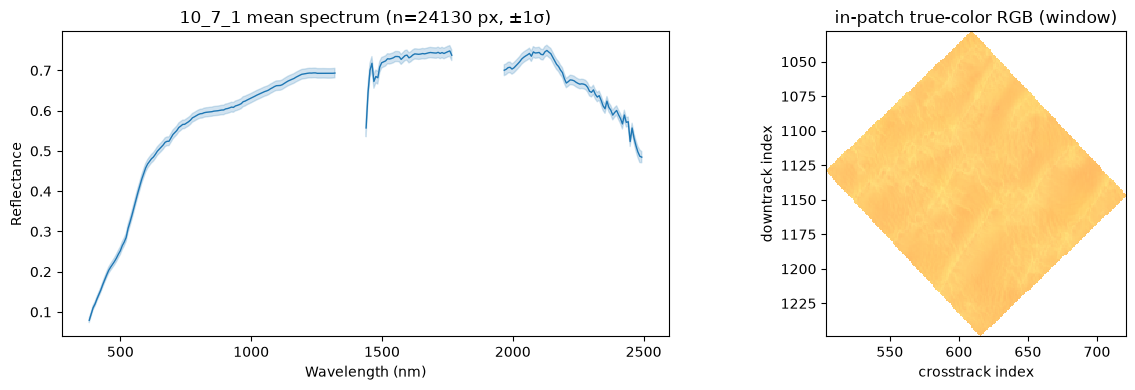

In [9]:
import warnings
import numpy as np
import geopandas as gpd
import shapely
import xarray as xr
import earthaccess
from scipy.spatial import KDTree
import logging
logging.getLogger("fsspec").setLevel(logging.WARNING)
import matplotlib.pyplot as plt

# ============================================================
# CONFIG  (assumes patches_gdf, patch_granules, PICS_NAME,
#          EMIT_PRODUCTS, DATE_START_ALL/END_ALL exist)
# ============================================================
EXTRACT_PATCH_ID = "10_7_1"      # patch to extract; must exist in patches_gdf
EXTRACT_PRODUCT  = "L2A_RFL"     # RFL only for now
FILL = -9999.0


def get_patch_4326(patch_id):
    """Return the patch polygon reprojected to EPSG:4326 (tilted quad)."""
    sub = patches_gdf[patches_gdf["patch_id"] == patch_id]
    if sub.empty:
        raise ValueError(f"patch_id '{patch_id}' not in patches_gdf.")
    return gpd.GeoSeries([sub.geometry.iloc[0]], crs=patches_gdf.crs).to_crs(4326).iloc[0]


def open_emit_l2a(granule):
    """Open an EMIT L2A RFL granule via earthaccess (authenticated streaming),
    reading groups by name. Returns a dict with correctly-shaped arrays:
        lon, lat, elev : (downtrack, crosstrack)
        reflectance    : (downtrack, crosstrack, bands)  lazy DataArray
        wavelengths    : (bands,) nm
    `granule` is an earthaccess DataGranule (search result), NOT a URL string.
    """
    fobj = earthaccess.open([granule])[0]

    root = xr.open_dataset(fobj, engine="h5netcdf")
    refl = root["reflectance"]                       # ('downtrack','crosstrack','bands')

    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    wavelengths = np.asarray(bp["wavelengths"].data, dtype="float64")

    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    lon = np.asarray(loc["lon"].data, dtype="float64")   # (downtrack, crosstrack)
    lat = np.asarray(loc["lat"].data, dtype="float64")

    return {"root": root, "reflectance": refl,
            "wavelengths": wavelengths, "lon": lon, "lat": lat}


def patch_pixel_mask(patch_4326, lon, lat, fill=FILL):
    """Boolean (downtrack, crosstrack) mask of pixels inside the patch polygon.
    KDTree pre-filters to a disk around the patch centroid; shapely makes the
    exact point-in-polygon call on the candidates."""
    valid = (lon != fill) & (lat != fill) & np.isfinite(lon) & np.isfinite(lat)

    cx, cy = patch_4326.centroid.x, patch_4326.centroid.y
    w, s, e, n = patch_4326.bounds
    radius = 0.5 * np.hypot(e - w, n - s) * 1.10     # half-diagonal + 10% collar

    flat_idx = np.flatnonzero(valid)
    if flat_idx.size == 0:
        return np.zeros(lon.shape, dtype=bool)
    pts = np.column_stack([lon.ravel()[flat_idx], lat.ravel()[flat_idx]])

    tree = KDTree(pts)
    cand_local = tree.query_ball_point([cx, cy], r=radius)
    if not cand_local:
        return np.zeros(lon.shape, dtype=bool)

    cand_flat = flat_idx[np.asarray(cand_local)]
    inside = shapely.contains_xy(patch_4326,
                                 lon.ravel()[cand_flat],
                                 lat.ravel()[cand_flat])
    mask = np.zeros(lon.size, dtype=bool)
    mask[cand_flat[inside]] = True
    return mask.reshape(lon.shape)


def extract_patch(refl, mask, fill_values=(-9999.0, -0.01), fill=None):
    if not mask.any():
        return None, None, 0
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    block = refl[r0:r1, c0:c1, :].values
    submask = mask[r0:r1, c0:c1]
    pix = block[submask, :].astype("float64")
    pix[np.isclose(pix, -9999.0)] = np.nan
    pix[np.isclose(pix, -0.01, atol=1e-4)] = np.nan
    mean_spec = np.nanmean(pix, axis=0)
    return mean_spec, pix, pix.shape[0]

def nearest_band(wl, target_nm):
    """Index of the channel closest to target_nm."""
    return int(np.argmin(np.abs(wl - target_nm)))


def patch_rgb(refl, mask, wl, fill_values=(-9999.0, -0.01),
              rgb_nm=(650.0, 550.0, 450.0), vmin=0.0, vmax=0.45):
    """True-color RGB of in-patch pixels. Uses a SHARED reflectance range
    across channels so the inter-band brightness ratio (i.e. the real color)
    is preserved."""
    if not mask.any():
        return None, None
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    submask = mask[r0:r1, c0:c1]

    bidx = [nearest_band(wl, t) for t in rgb_nm]
    block = refl[r0:r1, c0:c1, bidx].values.astype("float64")
    for fv in fill_values:
        block[np.isclose(block, fv, atol=1e-4)] = np.nan

    # SHARED linear stretch (same vmin/vmax for all three channels) -> true color
    rgb = np.clip((block - vmin) / (vmax - vmin), 0, 1)

    alpha = submask.astype("float64")
    return np.dstack([rgb, alpha]), submask
    
# ============================================================
# DRIVER — one granule, validate the mechanic
# ============================================================
patch_4326 = get_patch_4326(EXTRACT_PATCH_ID)

# Granule UR that fully covers this patch (from the cached scene list).
urs = patch_granules[EXTRACT_PATCH_ID][EXTRACT_PRODUCT]
if not urs:
    raise ValueError(f"No fully-covering {EXTRACT_PRODUCT} granules for {EXTRACT_PATCH_ID}.")
target_ur = urs[0]

# Resolve the granule OBJECT (not URL) for that UR.
match = [g for g in earthaccess.search_data(
            short_name=EMIT_PRODUCTS[EXTRACT_PRODUCT],
            temporal=(DATE_START_ALL, DATE_END_ALL),
            bounding_box=tuple(patch_4326.bounds),
            count=-1)
         if g["umm"].get("GranuleUR") == target_ur]
if not match:
    raise RuntimeError(f"Could not resolve granule for {target_ur}")
granule = match[0]
print(f"Patch {EXTRACT_PATCH_ID} | granule {target_ur}")

emit = open_emit_l2a(granule)
lon, lat = emit["lon"], emit["lat"]
refl, wl = emit["reflectance"], emit["wavelengths"]
print("reflectance dims/shape:", refl.dims, refl.shape)

mask = patch_pixel_mask(patch_4326, lon, lat)
mean_spec, pix_stack, n_pix = extract_patch(refl, mask)

patch_km = int(EXTRACT_PATCH_ID.split("_")[0])
theoretical = (patch_km * 1000 / 60) ** 2
print(f"In-patch pixels: {n_pix}  (theoretical full {patch_km} km @60m ~= {theoretical:,.0f})")

# ============================================================
# QUICK VALIDATION PLOTS  (replaces the previous block)
# ============================================================
if mean_spec is not None:
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4))

    sd = np.nanstd(pix_stack, axis=0)
    axL.plot(wl, mean_spec, lw=1, color="C0")
    axL.fill_between(wl, mean_spec - sd, mean_spec + sd, color="C0", alpha=0.2)
    axL.set_xlabel("Wavelength (nm)"); axL.set_ylabel("Reflectance")
    axL.set_title(f"{EXTRACT_PATCH_ID} mean spectrum (n={n_pix} px, ±1σ)")

    rgba, _ = patch_rgb(refl, mask, wl)

    # bounding-window indices in the FULL scene, for true axis labels
    rows, cols = np.where(mask)
    r0, r1, c0, c1 = rows.min(), rows.max()+1, cols.min(), cols.max()+1
    # extent = (left, right, bottom, top); top<bottom flips y so downtrack
    # increases downward, matching imshow's default row order
    axR.imshow(rgba, interpolation="nearest", extent=(c0, c1, r1, r0))
    axR.set_xlabel("crosstrack index")
    axR.set_ylabel("downtrack index")
    axR.set_title("in-patch true-color RGB (window)")
    plt.tight_layout(); plt.show()
else:
    print("No pixels fell inside the patch — check CRS/containment.")

## Wrapper that pulls spectra and plots RGB for all scenes covering a patch

2026-06-23 15:07:56,519  INFO      earthaccess.api  Granules found: 20
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:08:05,744  INFO      earthaccess.store  Opening 1 granules, approx size: 3.49 GB


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

C:\Users\huckr\AppData\Local\Temp\ipykernel_79300\622998415.py:93: RuntimeWarning: Mean of empty slice
  mean_spec = np.nanmean(pix, axis=0)
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:08:54,083  INFO      earthaccess.store  Opening 1 granules, approx size: 3.5 GB


  EMIT_L2A_RFL_001_20220823T105327_2223507_009  n=24130


... (60 outputs left out)

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

  EMIT_L2A_RFL_001_20260614T120829_2616508_018  n=24193

10_7_1: extracted 13 acquisition(s).


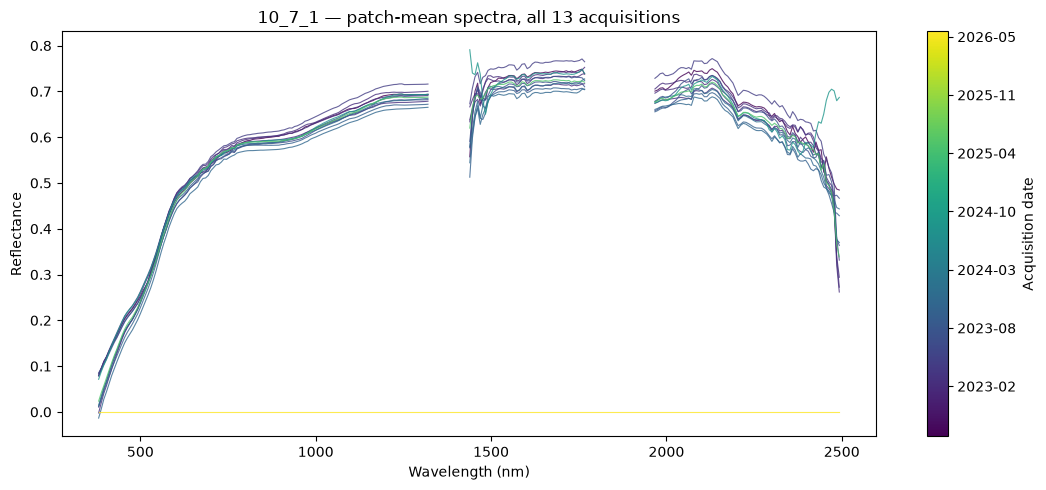

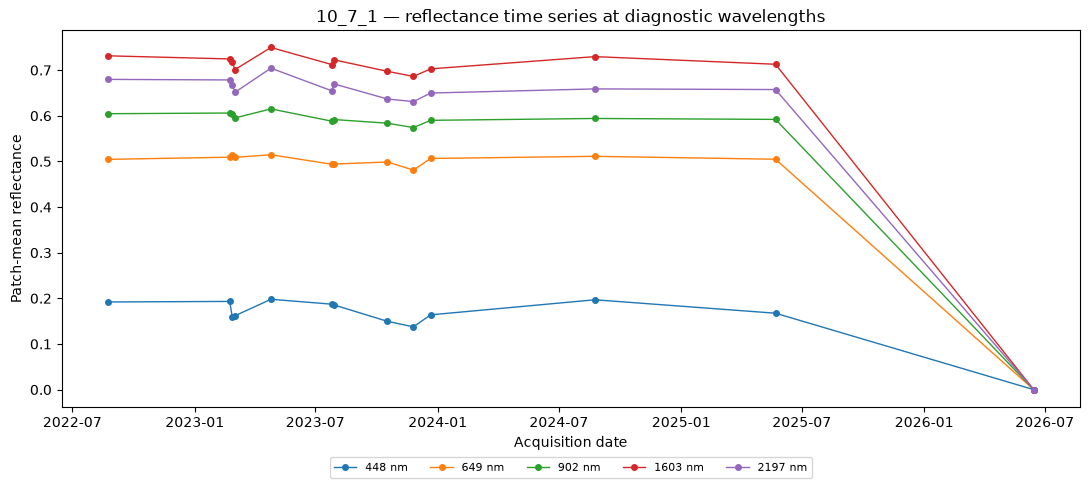

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:17:51,685  INFO      earthaccess.store  Opening 1 granules, approx size: 3.49 GB


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:18:39,030  INFO      earthaccess.store  Opening 1 granules, approx size: 3.5 GB


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

... (3 outputs left out)

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

KeyboardInterrupt: 

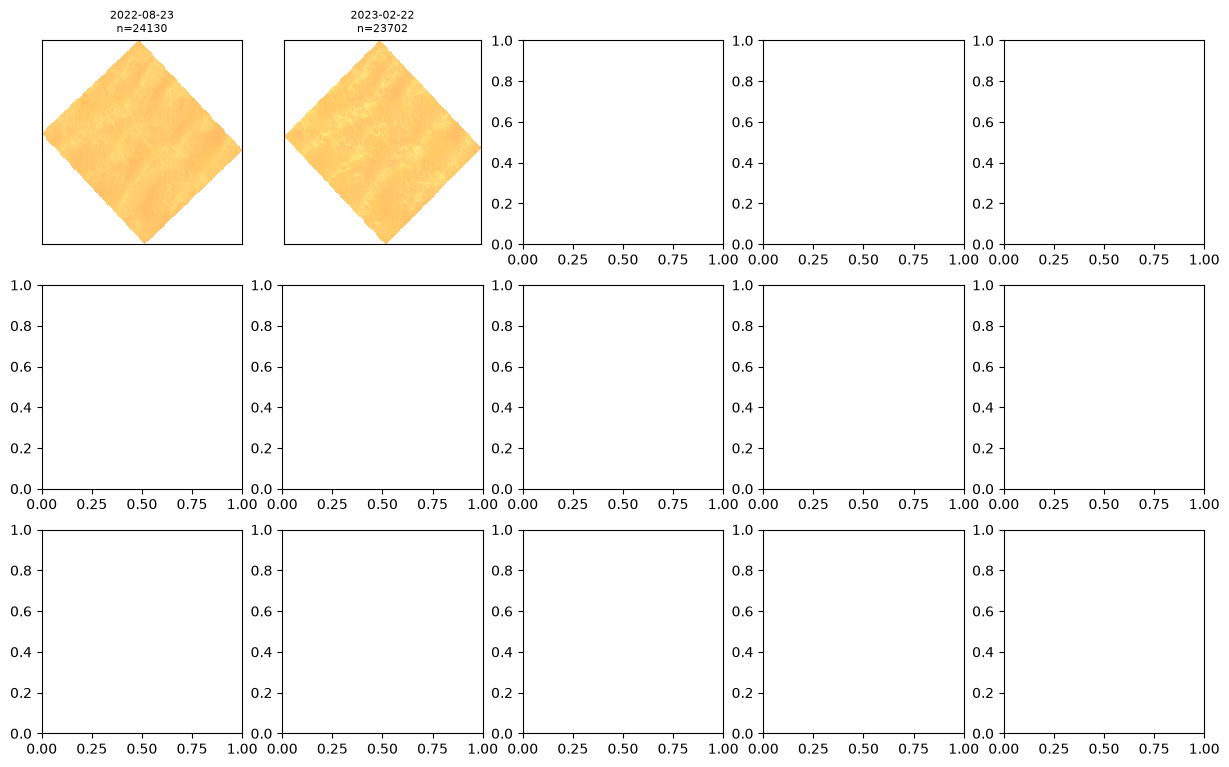

In [14]:
import pandas as pd
from datetime import datetime

# ============================================================
# CONFIG
# ============================================================
TS_PATCH_ID  = "10_7_1"      # patch to extract the full time series for
TS_PRODUCT   = "L2A_RFL"
RGB_VMIN, RGB_VMAX = 0.0, 0.45   # fixed stretch, shared across all scenes


def acquisition_time_from_ur(ur):
    """Parse acquisition datetime from an EMIT granule UR
    (…_YYYYMMDDTHHMMSS_…)."""
    import re
    m = re.search(r"_(\d{8}T\d{6})_", ur)
    return datetime.strptime(m.group(1), "%Y%m%dT%H%M%S") if m else None


def extract_patch_timeseries(patch_id, product, date_range=None):
    """Run the single-granule extraction over EVERY granule that fully covers
    the patch. Returns a dict of per-acquisition results, sorted by time."""
    patch_4326 = get_patch_4326(patch_id)

    urs = patch_granules[patch_id][product]
    if not urs:
        raise ValueError(f"No fully-covering {product} granules for {patch_id}.")

    # Cache ALL granule objects for this patch in ONE search (not per-UR).
    if date_range is None:
        date_range = (DATE_START_ALL, DATE_END_ALL)
    all_g = earthaccess.search_data(
        short_name=EMIT_PRODUCTS[product],
        bounding_box=tuple(patch_4326.bounds),
        temporal=date_range,
        count=-1,
    )
    g_by_ur = {g["umm"].get("GranuleUR"): g for g in all_g}

    records = []
    for ur in urs:
        granule = g_by_ur.get(ur)
        if granule is None:
            print(f"  skip {ur}: object not found in search cache")
            continue
        try:
            emit = open_emit_l2a(granule)
            mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
            mean_spec, pix_stack, n_pix = extract_patch(emit["reflectance"], mask)
        except Exception as ex:
            print(f"  skip {ur}: {type(ex).__name__}: {ex}")
            continue
        if mean_spec is None or n_pix == 0:
            print(f"  skip {ur}: no in-patch pixels")
            continue

        records.append({
            "ur": ur,
            "datetime": acquisition_time_from_ur(ur),
            "n_pixels": n_pix,
            "mean_spec": mean_spec,
            "std_spec": np.nanstd(pix_stack, axis=0),
            "wavelengths": emit["wavelengths"],
        })
        print(f"  {ur}  n={n_pix}")

    records.sort(key=lambda r: r["datetime"] or datetime.min)
    print(f"\n{patch_id}: extracted {len(records)} acquisition(s).")
    return records, g_by_ur


# ============================================================
# RUN
# ============================================================
ts, g_by_ur = extract_patch_timeseries(TS_PATCH_ID, TS_PRODUCT)

if not ts:
    raise RuntimeError("No acquisitions extracted.")

wl = ts[0]["wavelengths"]
mean_matrix = np.vstack([r["mean_spec"] for r in ts])   # (n_acq, n_bands)
times = [r["datetime"] for r in ts]

# ============================================================
# FIGURE 1 — all mean spectra, colored by acquisition date
# ============================================================
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(11, 5))
tnum = mdates.date2num(times)
norm = Normalize(vmin=min(tnum), vmax=max(tnum))
cmap = cm.viridis

for r, t in zip(ts, tnum):
    plot_spec = np.where(np.isfinite(r["mean_spec"]), r["mean_spec"], np.nan)
    ax.plot(wl, plot_spec, lw=0.8, color=cmap(norm(t)), alpha=0.8)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title(f"{TS_PATCH_ID} — patch-mean spectra, all {len(ts)} acquisitions")
sm = cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
cbar.set_label("Acquisition date")
plt.tight_layout(); plt.show()

# ============================================================
# FIGURE 2 — per-band reflectance vs time at a few diagnostic wavelengths
# ============================================================
diag_nm = [450, 650, 900, 1600, 2200]   # blue, red, NIR, SWIR1, SWIR2
fig, ax = plt.subplots(figsize=(11, 5))
for target in diag_nm:
    bidx = nearest_band(wl, target)
    series = mean_matrix[:, bidx]
    ax.plot(times, series, marker="o", ms=4, lw=1, label=f"{wl[bidx]:.0f} nm")
ax.set_xlabel("Acquisition date")
ax.set_ylabel("Patch-mean reflectance")
ax.set_title(f"{TS_PATCH_ID} — reflectance time series at diagnostic wavelengths")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

# ============================================================
# FIGURE 3 — RGB contact sheet, one panel per acquisition (shared fixed stretch)
# ============================================================
import math
n = len(ts)
ncols = min(5, n)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False)
axes = axes.ravel()
patch_4326 = get_patch_4326(TS_PATCH_ID)

for ax, r in zip(axes, ts):
    g = g_by_ur[r["ur"]]                       # reuse the cached granule object
    emit = open_emit_l2a(g)
    mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
    rgba, _ = patch_rgb(emit["reflectance"], mask, emit["wavelengths"],
                        vmin=RGB_VMIN, vmax=RGB_VMAX)
    if rgba is not None:
        ax.imshow(rgba, interpolation="nearest")
    ax.set_title(f"{r['datetime']:%Y-%m-%d}\nn={r['n_pixels']}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes[n:]:
    ax.axis("off")
fig.suptitle(f"{TS_PATCH_ID} — true-color RGB per acquisition (fixed stretch)",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

2026-06-23 15:21:10,807  INFO      earthaccess.api  Granules found: 20
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:21:11,169  INFO      earthaccess.store  Opening 1 granules, approx size: 1.83 GB


Patch 10_7_1 | granule EMIT_L1B_RAD_001_20220823T105327_2223507_009


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

radiance dims/shape: ('downtrack', 'crosstrack', 'bands') (1280, 1242, 285)
In-patch pixels: 24130  (theoretical full 10 km @60m ~= 27,778)


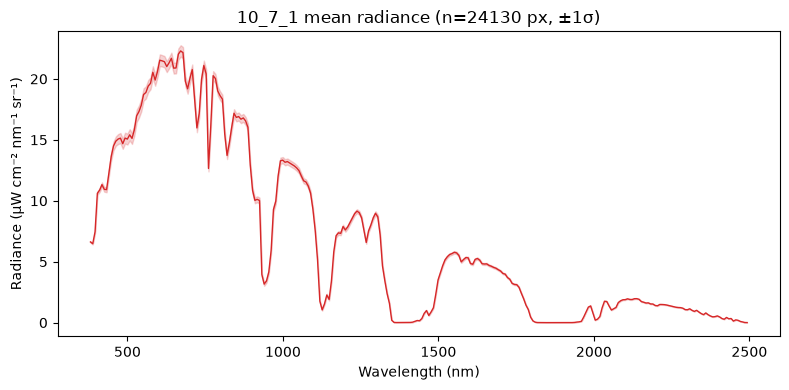

In [15]:
# ============================================================
# CONFIG  (assumes patches_gdf, patch_granules, PICS_NAME,
#          EMIT_PRODUCTS, DATE_START_ALL/END_ALL, patch_pixel_mask,
#          get_patch_4326, nearest_band exist from the RFL script)
# ============================================================
EXTRACT_PATCH_ID = "10_7_1"      # patch to extract; must exist in patches_gdf
RAD_PRODUCT      = "L1B_RAD"
FILL = -9999.0


def open_emit_l1b(granule):
    """Open an EMIT L1B RAD granule via earthaccess (authenticated streaming),
    reading groups by name. Returns a dict:
        lon, lat   : (downtrack, crosstrack)
        radiance   : (downtrack, crosstrack, bands)  lazy DataArray
        wavelengths, fwhm : (bands,)
    `granule` is an earthaccess DataGranule, NOT a URL string.
    """
    fobj = earthaccess.open([granule])[0]

    root = xr.open_dataset(fobj, engine="h5netcdf")
    rad = root["radiance"]                            # ('downtrack','crosstrack','bands')

    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    wavelengths = np.asarray(bp["wavelengths"].data, dtype="float64")
    fwhm = np.asarray(bp["fwhm"].data, dtype="float64") if "fwhm" in bp else None

    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    lon = np.asarray(loc["lon"].data, dtype="float64")
    lat = np.asarray(loc["lat"].data, dtype="float64")

    return {"root": root, "radiance": rad, "wavelengths": wavelengths,
            "fwhm": fwhm, "lon": lon, "lat": lat}


def extract_patch_rad(rad, mask, fill_values=(-9999.0,)):
    """Stream only the masked block. Return (mean_spectrum, pixel_stack, n_pixels).
    L1B radiance: only -9999 no-data fill is masked (no -0.01 absorption flag)."""
    if not mask.any():
        return None, None, 0
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    block = rad[r0:r1, c0:c1, :].values
    submask = mask[r0:r1, c0:c1]
    pix = block[submask, :].astype("float64")
    for fv in fill_values:
        pix[np.isclose(pix, fv)] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_spec = np.nanmean(pix, axis=0)
    return mean_spec, pix, pix.shape[0]


# ============================================================
# DRIVER — one granule, validate the mechanic
# ============================================================
patch_4326 = get_patch_4326(EXTRACT_PATCH_ID)

urs = patch_granules[EXTRACT_PATCH_ID][RAD_PRODUCT]
if not urs:
    raise ValueError(f"No fully-covering {RAD_PRODUCT} granules for {EXTRACT_PATCH_ID}.")
target_ur = urs[0]

match = [g for g in earthaccess.search_data(
            short_name=EMIT_PRODUCTS[RAD_PRODUCT],
            temporal=(DATE_START_ALL, DATE_END_ALL),
            bounding_box=tuple(patch_4326.bounds),
            count=-1)
         if g["umm"].get("GranuleUR") == target_ur]
if not match:
    raise RuntimeError(f"Could not resolve granule for {target_ur}")
granule = match[0]
print(f"Patch {EXTRACT_PATCH_ID} | granule {target_ur}")

emit = open_emit_l1b(granule)
lon, lat = emit["lon"], emit["lat"]
rad, wl = emit["radiance"], emit["wavelengths"]
print("radiance dims/shape:", rad.dims, rad.shape)

mask = patch_pixel_mask(patch_4326, lon, lat)
mean_spec, pix_stack, n_pix = extract_patch_rad(rad, mask)

patch_km = int(EXTRACT_PATCH_ID.split("_")[0])
theoretical = (patch_km * 1000 / 60) ** 2
print(f"In-patch pixels: {n_pix}  (theoretical full {patch_km} km @60m ~= {theoretical:,.0f})")

# ============================================================
# QUICK VALIDATION PLOT — radiance spectrum
# ============================================================
if mean_spec is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    sd = np.nanstd(pix_stack, axis=0)
    ax.plot(wl, mean_spec, lw=1, color="C3")
    ax.fill_between(wl, mean_spec - sd, mean_spec + sd, color="C3", alpha=0.2)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Radiance (µW cm⁻² nm⁻¹ sr⁻¹)")   # confirm units from file attrs
    ax.set_title(f"{EXTRACT_PATCH_ID} mean radiance (n={n_pix} px, ±1σ)")
    plt.tight_layout(); plt.show()
else:
    print("No pixels fell inside the patch — check CRS/containment.")

In [17]:
fobj = earthaccess.open([granule])[0]
root = xr.open_dataset(fobj, engine="h5netcdf")

print("=== ROOT GROUP ===")
print("data_vars:", list(root.data_vars))
print("dims:", dict(root.sizes))
print("coords:", list(root.coords))

# 1. Is there a variable literally named 'radiance' in root?
has_radiance = "radiance" in root.data_vars
print(f"\n'radiance' in root data_vars? {has_radiance}")

if has_radiance:
    rad = root["radiance"]
    print(f"  dims:  {rad.dims}")
    print(f"  shape: {rad.shape}")

    # 2. Dims match the expected (downtrack, crosstrack, bands)?
    expected = ("downtrack", "crosstrack", "bands")
    print(f"\n  dims == {expected}? {rad.dims == expected}")
    if rad.dims != expected:
        print("  !! dim names/order differ -- adjust indexing accordingly")

    # 3. Cross-check the band axis length against the wavelength count
    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    n_wl = bp["wavelengths"].size
    band_len = rad.sizes.get("bands", None)
    print(f"\n  bands dim length: {band_len}")
    print(f"  wavelengths length: {n_wl}")
    print(f"  match? {band_len == n_wl}")

    # 4. Confirm the two spatial dims match the geolocation arrays
    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    print(f"\n  lon shape: {loc['lon'].shape}")
    print(f"  radiance spatial dims: ({rad.sizes.get('downtrack')}, {rad.sizes.get('crosstrack')})")
else:
    print("  Available data_vars instead:", list(root.data_vars))
    print("  -> the radiance variable is named something else; use that name.")

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:30:59,659  INFO      earthaccess.store  Opening 1 granules, approx size: 1.83 GB


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

=== ROOT GROUP ===
data_vars: ['radiance']
dims: {'downtrack': 1280, 'crosstrack': 1242, 'bands': 285}
coords: []

'radiance' in root data_vars? True
  dims:  ('downtrack', 'crosstrack', 'bands')
  shape: (1280, 1242, 285)

  dims == ('downtrack', 'crosstrack', 'bands')? True

  bands dim length: 285
  wavelengths length: 285
  match? True

  lon shape: (1280, 1242)
  radiance spatial dims: (1280, 1242)


In [18]:
import geopandas as gpd
from pathlib import Path

# ---- config ----
EXPORT_PATCH_ID = "10_7_1"
OUT_DIR = r"C:\Users\huckr\Desktop\JPL\Data\ROIs\patch_shp_for_AppEEARS"
# ----------------

sub = patches_gdf[patches_gdf["patch_id"] == EXPORT_PATCH_ID].copy()
if sub.empty:
    raise ValueError(f"patch_id '{EXPORT_PATCH_ID}' not in patches_gdf.")

# Reproject UTM -> EPSG:4326 for AppEEARS (it expects geographic coords).
sub_4326 = sub.to_crs("EPSG:4326")

# Keep attributes short: shapefile DBF truncates field names to 10 chars.
keep = [c for c in ["patch_id", "size_km", "row", "col"] if c in sub_4326.columns]
sub_4326 = sub_4326[keep + ["geometry"]]

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
out_path = str(Path(OUT_DIR) / f"patch_{EXPORT_PATCH_ID}.shp")
sub_4326.to_file(out_path, driver="ESRI Shapefile")

print(f"Wrote {out_path}")
print(f"CRS: {sub_4326.crs}")
print(f"Bounds (lon/lat): {sub_4326.total_bounds}")
print("Sidecar files (.shp/.shx/.dbf/.prj) written alongside.")

2026-06-23 16:04:21,327  INFO      pyogrio._io  Created 1 records


Wrote C:\Users\huckr\Desktop\JPL\Data\ROIs\patch_shp_for_AppEEARS\patch_10_7_1.shp
CRS: EPSG:4326
Bounds (lon/lat): [23.07827105 28.28298973 23.18201721 28.37478786]
Sidecar files (.shp/.shx/.dbf/.prj) written alongside.
